# Plot NN Results From Saved Data

Load the saved training histories and recreate the plots without rerunning the neural-network experiments.

In [7]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt

In [8]:
DATA_FILE = Path("nn_results.pkl")
if not DATA_FILE.exists():
    DATA_FILE = Path("NN") / DATA_FILE

with DATA_FILE.open("rb") as result_file:
    results = pickle.load(result_file)

histories_by_label = results["histories"]
labels = results["labels"]
histories = [histories_by_label[label] for label in labels]

print(f"Loaded {len(histories)} histories from {DATA_FILE}")

Loaded 7 histories from nn_results.pkl


In [9]:
# These values match the original experiment notebook.
adam_color = "#E8601C"
gladssn_color = "#9B8AC4"
gladssn_lazy_1_color = "#88A5DD"
gladssn_lazy_2_color = "#8DCBE4"
gladssn_lazy_3_color = "#C2E3D2"
gladssn_lazy_4_color = "#DDECBF"
gladssn_lazy_5_color = "#F2E1D0"

colors = [
    adam_color,
    gladssn_color,
    gladssn_lazy_1_color,
    gladssn_lazy_2_color,
    gladssn_lazy_3_color,
    gladssn_lazy_4_color,
    gladssn_lazy_5_color,
]
line_widths = [1.0] * len(histories)
line_styles = ["-"] * len(histories)
marker_cycle = ["None", "^", "D", "x", "v", "h", "1"]

In [10]:
def plot_graphs(list_of_times, list_of_grads, list_of_labels, number_of_methods, y_label, line_styles, which_measure):
    markevery_numbers = [15000] * len(list_of_times)
    if number_of_methods is None:
        number_of_methods = len(list_of_times)
    marker_size = 2
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    for i in range(number_of_methods):
        axes[0].semilogy(
            list_of_times[i],
            list_of_grads[i],
            label=list_of_labels[i],
            color=colors[i],
            linewidth=1,
            linestyle=line_styles[i],
            markersize=2 * marker_size,
            markevery=markevery_numbers[i],
        )
    axes[0].set_xlabel("Runtime (s)")
    axes[0].set_ylabel(y_label)
    axes[0].set_xlim(0, 100)
    axes[0].grid(True)

    for i in range(number_of_methods):
        axes[1].semilogy(
            list_of_grads[i],
            label=list_of_labels[i],
            color=colors[i],
            linewidth=1,
            linestyle=line_styles[i],
            marker=marker_cycle[i],
            markersize=marker_size,
            markevery=markevery_numbers[i],
        )
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel(y_label)
    axes[1].set_xlim(0, 13000)
    handles, legend_labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, legend_labels, loc="upper center", ncol=3)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.savefig("plot_NN_" + which_measure + ".pdf")
    plt.show()

In [11]:
def plot_penalty(list_of_times, list_of_grads, list_of_labels, number_of_methods, y_label, line_styles, which_measure):
    markevery_numbers = [100000, 15, 50, 50, 50, 50, 50]
    if number_of_methods is None:
        number_of_methods = len(list_of_times)
    marker_size = 2
    plt.figure(figsize=(6, 4))

    for i in range(number_of_methods):
        plt.semilogy(
            list_of_grads[i],
            label=list_of_labels[i],
            color=colors[i],
            linewidth=1,
            linestyle=line_styles[i],
            markersize=marker_size,
            markevery=markevery_numbers[i],
        )
    plt.xlim(0, 4000)
    plt.xlabel("Epoch")
    plt.ylabel(y_label)
    plt.grid(True, which="both", linestyle="--", linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    plt.savefig("plot_NN_" + which_measure + ".pdf")
    plt.show()

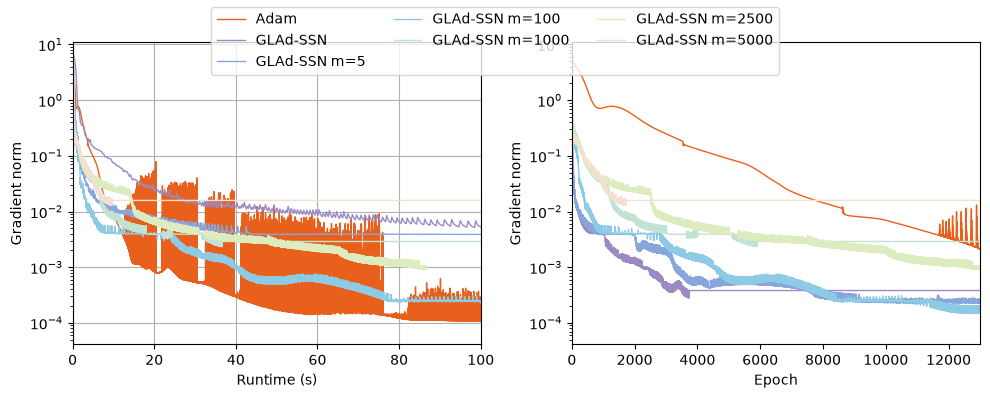

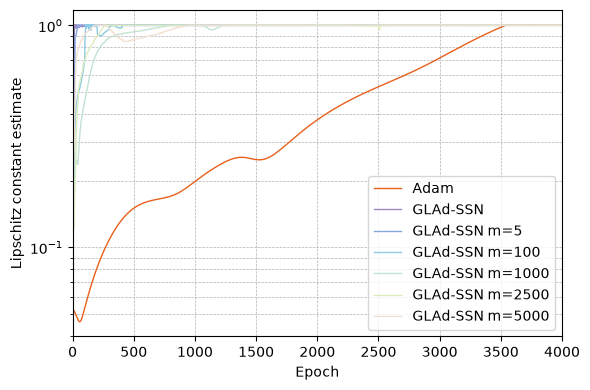

In [12]:
all_methods = list(labels)
times_list = [histories_by_label[method]["time"] for method in all_methods]
grads_list = [histories_by_label[method]["grad_norm"] for method in all_methods]
hess_op_norm_list = [histories_by_label[method]["hessian_norm"] for method in all_methods]

plot_graphs(
    times_list,
    grads_list,
    all_methods,
    None,
    "Gradient norm",
    line_styles,
    which_measure="grad_norm",
)
plot_penalty(
    times_list,
    hess_op_norm_list,
    all_methods,
    None,
    "Lipschitz constant estimate",
    line_styles,
    which_measure="hess_op_norm",
)